# Úkol č. 2 - Využití neuronových sítí

  * Termíny jsou uvedeny na [courses.fit.cvut.cz/BI-ML2/homeworks/index.html](https://courses.fit.cvut.cz/BI-ML2/homeworks/index.html).
  * Pokud odevzdáte úkol po prvním termínu ale před nejzazším termínem, budete penalizování -12 body, pozdější odevzdání je bez bodu.
  * V rámci tohoto úkolu musíte sestrojit vhodný model neuronové sítě pro vícetřídou klasifikaci.
  * Část bodů získáte za správné vypracování a část bodů získáte za výslednou přesnost Vašeho modelu na evaluačních datech.
    
> **Úkoly jsou zadány tak, aby Vám daly prostor pro invenci. Vymyslet _jak přesně_ budete úkol řešit, je důležitou součástí zadání a originalita či nápaditost bude také hodnocena!**

Využívejte buňky typu `Markdown` k vysvětlování Vašeho postupu. Za nepřehlednost budou strhávány body.

## Zdroj dat

 * Zdrojem dat jsou soubory `train.csv` a `evaluate.csv`.
 * Jedná se o obrázky 32x32 pixelů ve stupních šedi, které byly nějakým způsobem vyrobeny z [Fashion Mnist datasetu](https://www.kaggle.com/datasets/zalando-research/fashionmnist).
 * Soubor `train.csv` obsahuje trénovací data.
 * Cílová (vysvětlovaná) proměnná se jmenuje **label**.
 * Soubor `evaluate.csv` obsahuje testovací data bez hodnot skutečných labelů.

## Pokyny k vypracování (max 18 bodů)

**Body zadání**, za jejichž (poctivé) vypracování získáte **18 bodů**:
  * V notebooku načtěte data ze souboru `train.csv`. Vhodným způsobem si je rozdělte na podmnožiny, které Vám poslouží pro trénování, porovnávání modelů a následnou predikci výkonnosti finálního modelu.
  * Proveďte základní průzkum dat a svá pozorování diskutujte. Některé obrázky také zobrazte.
  * Sestrojte a natrénujte několik variant modelu dopředné neuronové sítě. Přitom v rámci výpočetních možností:
      * Okomentujte vhodnost daného modelu pro daný typ úlohy.
      * Experimentujte s různými hloubkami a velikosmi vrstev.
      * Experimentujte se standardizací/normalizací dat.
      * Experimentujte s různými optimalizačními metodami.
      * Experimentujte s různými regularizačními technikami.
      * Získané výsledky vždy řádně okomentujte.
<br/><br/>
  * Sestrojte model konvoluční neuronové sítě. Přitom v rámci výpočetních možností:
      * Okomentujte vhodnost daného modelu pro daný typ úlohy.
      * Experimentujte s různými hloubkami a velikosmi vrstev.
      * Experimentujte se standardizací/normalizací dat.
      * Experimentujte s různými optimalizačními metodami.
      * Experimentujte s různými regularizačními technikami.
      * Získané výsledky vždy řádně okomentujte.
    <br/><br/>
  * Ze všech zkoušených možností vyberte finální model a odhadněte, jakou přesnost můžete očekávat na nových datech, která jste doposud neměli k dispozici.
  
  * Nakonec načtěte vyhodnocovací data ze souboru`evaluate.csv`. Pomocí finálního modelu napočítejte predikce pro tyto data (vysvětlovaná proměnná v nich již není). Vytvořte soubor `results.csv`, ve kterém získané predikce uložíte do sloupce **label** a identifikátory do sloupce **ID**. Tento soubor též odevzdejte (uložte do projektu vedle notebooku).
   
   * Ukázka prvních řádků souboru `results.csv`:
  
```
ID,label
0,0
1,1
...
```

## Vyhodnocovací část (max 7 bodů)
Za přesnost (accuraccy) na odevzdaných predikcích pro vyhodnocovací množnu získáte dalších max **7 bodů**.

Označíme-li $A$ přesnost, které jste dosáhli, zaokrouhlenou na 2 desetinná místa, akumulují se výsledné body podle následujících pravidel:
* pokud $A \geq 0.80$ obdržíte +1 bod
* pokud $A \geq 0.83$ obdržíte +1 bod
* pokud $A \geq 0.86$ obdržíte +1 bod
* pokud $A \geq 0.87$ obdržíte +1 bod
* pokud $A \geq 0.88$ obdržíte +1 bod
* pokud $A \geq 0.89$ obdržíte +1 bod
* pokud $A \geq 0.90$ obdržíte +1 bod

**Příklad:** Pokud bude Vaše přesnost 0.856, vyjde A = 0.86 a vy získáte 3 body.


## Poznámky k odevzdání

  * Řiďte se pokyny ze stránky https://courses.fit.cvut.cz/BI-ML2/homeworks/index.html.
  * Vytvořte i csv soubor `results.csv` s predikcemi a uložte ho v rámci projektu vedle ipython notebooku.

## 0. Libriries import

In [1]:
import pandas as pd
import math
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings
import torch
from torch.utils.data import TensorDataset, random_split
import torch
import torch.nn.functional as F
import gc
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torch import nn, optim
from tqdm import tqdm



random_seed = 42

## 1. Data preprocessing

In [2]:
df = pd.read_csv("train.csv")
print("Dataset sizes are: " + str(df.shape))

Dataset sizes are: (52500, 1025)


Let's see dataset overview:

In [3]:
display(df)

,pix1,pix2,pix3,pix4,pix5,pix6,pix7,pix8,pix9,pix10,...,pix1016,pix1017,pix1018,pix1019,pix1020,pix1021,pix1022,pix1023,pix1024,label
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7
1,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,0
2,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,6
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,3
4,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52495,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7
52496,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,6
52497,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,8
52498,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9


Describing our dataset.

In [4]:
df.describe()

,pix1,pix2,pix3,pix4,pix5,pix6,pix7,pix8,pix9,pix10,...,pix1016,pix1017,pix1018,pix1019,pix1020,pix1021,pix1022,pix1023,pix1024,label
count,52500.000000,52500.000000,52500.000000,52500.000000,52500.000000,52500.000000,52500.000000,52500.000000,52500.000000,52500.000000,...,52500.00000,52500.000000,52500.000000,52500.000000,52500.000000,52500.00000,52500.000000,52500.000000,52500.000000,52500.000000
mean,0.883333,0.883333,0.883333,0.883333,0.883333,0.883410,0.883467,0.883695,0.884686,0.887162,...,0.90499,0.906686,0.899943,0.889219,0.884171,0.88341,0.883352,0.883333,0.883333,4.498476
std,1.506764,1.506764,1.506764,1.506764,1.506764,1.506871,1.506957,1.507379,1.512250,1.542576,...,1.94179,2.065057,1.859559,1.594743,1.510982,1.50701,1.506784,1.506764,1.506764,2.874794
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,2.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,4.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.00000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,7.000000
max,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000,27.000000,66.000000,...,207.00000,206.000000,122.000000,93.000000,24.000000,11.00000,11.000000,11.000000,11.000000,9.000000


Controlling missing values

In [5]:
print("Missing values count: ", df.isnull().sum().sum())

Missing values count:  0


Let's see label distribution:

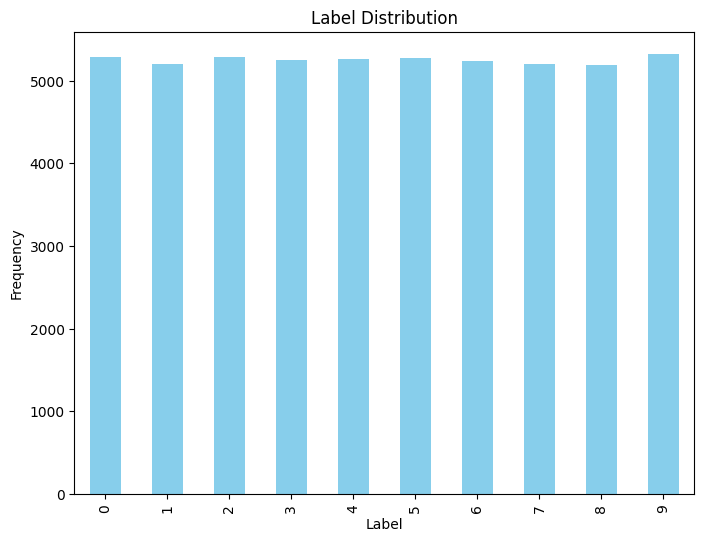

In [6]:
plt.figure(figsize=(8, 6))
df['label'].value_counts().sort_index().plot(kind='bar', color='skyblue')
plt.title("Label Distribution")
plt.xlabel("Label")
plt.ylabel("Frequency")
plt.show()

The distribution of the "label" variable is relatively uniform, as each label appears approximately the same number of times in the dataset.

### Images overview

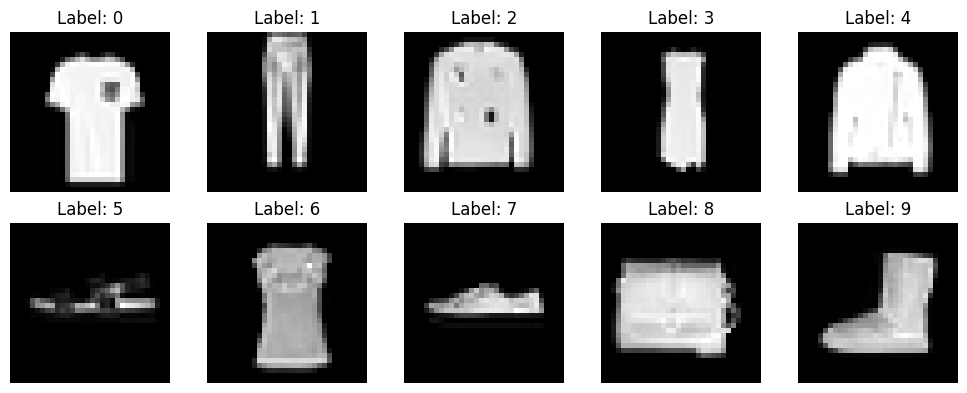

In [7]:
def plot_images(images, labels, ncols=5):
    n_images = len(images)
    nrows = (n_images + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2, nrows * 2))
    axes = axes.flatten()
    
    for i in range(n_images):
        ax = axes[i]
        img = images[i].reshape(32, 32) 
        ax.imshow(img, cmap='gray')
        ax.set_title(f"Label: {labels[i]}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

unique_labels = df['label'].unique() 
unique_labels = sorted(unique_labels)
sample_images = []
sample_labels = []

for label in unique_labels[:10]:  
    label_images = df[df['label'] == label]
    random_image = label_images.sample(1)  
    sample_images.append(random_image.drop(columns=["label"]).values[0])
    sample_labels.append(random_image['label'].values[0])

sample_images = np.array(sample_images)
sample_labels = np.array(sample_labels)

plot_images(sample_images, sample_labels)


Now we know that dataset looks clear and we can continue to data splitting.

In [8]:
X = df.drop(columns=["label"]).values.astype("float32")
y = df["label"].values.astype("int64") 
X = X / 255.0
X_tensor = torch.tensor(X)
y_tensor = torch.tensor(y)

train_dataset = TensorDataset(X_tensor, y_tensor)

def split_dataset(dataset, train_ratio=0.6, val_ratio=0.2, seed=42):
    total = len(dataset)
    train_len = int(train_ratio * total)
    val_len = int(val_ratio * total)
    test_len = total - train_len - val_len

    return random_split(dataset, [train_len, val_len, test_len],
                        generator=torch.Generator().manual_seed(seed))

train_set, val_set, test_set = split_dataset(train_dataset)

Prepare features and labels from the dataframe, normalize pixel values, convert to tensors, and wrap into a `TensorDataset`; then split the dataset into train, validation, and test sets with reproducibility via a fixed random seed.


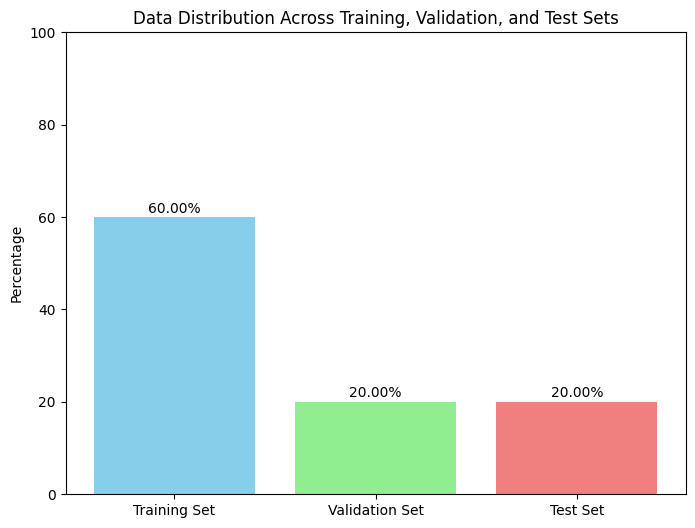

In [9]:
def plot_data_distribution(Xtrain, Xval, Xtest):
    sizes = [len(Xtrain), len(Xval), len(Xtest)]
    labels = ['Training Set', 'Validation Set', 'Test Set']
    percentages = [size / sum(sizes) * 100 for size in sizes]

    plt.figure(figsize=(8, 6))
    plt.bar(labels, percentages, color=['skyblue', 'lightgreen', 'lightcoral'])
    plt.title("Data Distribution Across Training, Validation, and Test Sets")
    plt.ylabel("Percentage")
    plt.ylim(0, 100)
    
    for i, v in enumerate(percentages):
        plt.text(i, v + 1, f"{v:.2f}%", ha='center', fontsize=10)

    plt.show()

plot_data_distribution(train_set, val_set, test_set)

In [10]:
batch_size = 64
training_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

Create data loaders for training, validation, and test sets with a batch size of 64; shuffling is applied only to the training set to improve generalization.


## 2. NN 

We use a basic feedforward neural network (MLP) with one hidden layer of 128 neurons, ReLU activation, and dropout (p=0.2) to reduce overfitting. This architecture is suitable for image classification tasks with flattened pixel inputs.

In [11]:
class MyNet(nn.Module):
    def __init__(self, input_dim=32*32, hidden_dim=128, output_dim=10, dropout_p=0.2):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout_p)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = x.flatten(start_dim=1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


### MyNet Architecture Description

- Accepts a 32×32 grayscale image input (flattened to 1024-dimensional vector).
- Passes through a fully connected layer: 1024 → 128 with ReLU activation.
- Applies dropout (default probability 0.2) for regularization.
- Final fully connected layer: 128 → 10, outputting class logits.
- Simple feedforward network suitable for basic image classification tasks.


In [12]:
def train_model(model, train_loader, val_loader, optimizer, name, loss_fn, num_epochs=30, patience=5, device='cpu'):
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_path = "models/" + "best_model_" + name + ".pt" 

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct_train = 0

        with tqdm(train_loader, desc=f"🟢 Training: {epoch+1}/{num_epochs}", unit="batch") as pbar:
            for inputs, labels in pbar:
                inputs, labels = inputs.to(device), labels.to(device)

                optimizer.zero_grad()
                outputs = model(inputs)
                loss = loss_fn(outputs, labels)
                loss.backward()
                optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                correct_train += (outputs.argmax(1) == labels).sum().item()

                avg_train_loss = running_loss / len(train_loader.dataset)
                train_accuracy = correct_train / len(train_loader.dataset)
                pbar.set_postfix(loss=avg_train_loss, accuracy=train_accuracy)

        avg_train_loss = running_loss / len(train_loader.dataset)
        train_accuracy = correct_train / len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        correct_val = 0

        with tqdm(val_loader, desc=f"🔵 Validation: {epoch+1}/{num_epochs}", unit="batch") as pbar:
            with torch.no_grad():
                for inputs, labels in pbar:
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = model(inputs)
                    loss = loss_fn(outputs, labels)

                    val_loss += loss.item() * inputs.size(0)
                    correct_val += (outputs.argmax(1) == labels).sum().item()

                    avg_val_loss = val_loss / len(val_loader.dataset)
                    val_accuracy = correct_val / len(val_loader.dataset)
                    pbar.set_postfix(loss=avg_val_loss, accuracy=val_accuracy)

        avg_val_loss = val_loss / len(val_loader.dataset)
        val_accuracy = correct_val / len(val_loader.dataset)

        print(f"🔹 TRAIN loss: {avg_train_loss:.4f}, acc: {train_accuracy:.4f}")
        print(f"🔹 VAL   loss: {avg_val_loss:.4f}, acc: {val_accuracy:.4f}")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_model_path)
            print("✅ New best model saved.")
        else:
            epochs_no_improve += 1
            print("⏸️ No improvement.")

        if epochs_no_improve >= patience:
            print("⏹️ Early stopping triggered.")
            break

    print(f"🔁 Training complete. Best val loss: {best_val_loss:.4f}")


In [13]:
model_MyNet_Adam = MyNet()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_MyNet_Adam.parameters())    
train_model(model_MyNet_Adam, training_loader, validation_loader, optimizer, "Adam", loss_fn, patience = 5)


🔵 Validation: 1/30: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 607.75batch/s, accuracy=0.753, loss=0.684]


🔹 TRAIN loss: 0.9219, acc: 0.6678
🔹 VAL   loss: 0.6843, acc: 0.7529
✅ New best model saved.


🔵 Validation: 2/30: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 576.13batch/s, accuracy=0.774, loss=0.608]


🔹 TRAIN loss: 0.6590, acc: 0.7621
🔹 VAL   loss: 0.6079, acc: 0.7743
✅ New best model saved.


🔵 Validation: 3/30: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 564.74batch/s, accuracy=0.795, loss=0.571]


...

🔹 TRAIN loss: 0.3324, acc: 0.8773
🔹 VAL   loss: 0.4525, acc: 0.8418
⏸️ No improvement.


🔵 Validation: 29/30: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 655.60batch/s, accuracy=0.84, loss=0.451]


🔹 TRAIN loss: 0.3280, acc: 0.8785
🔹 VAL   loss: 0.4507, acc: 0.8395
⏸️ No improvement.


🔵 Validation: 30/30: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 664.46batch/s, accuracy=0.848, loss=0.439]

🔹 TRAIN loss: 0.3285, acc: 0.8772
🔹 VAL   loss: 0.4388, acc: 0.8482
⏸️ No improvement.
🔁 Training complete. Best val loss: 0.4344


The model shows steady improvement in both training and validation accuracy, with the best performance achieved by epoch 27.The training process was stable, with consistent convergence.

This model is well-suited for the task due to its simple yet effective architecture, with one hidden layer and a dropout layer to prevent overfitting. The use of ReLU activation ensures non-linearity, allowing the model to capture complex patterns in the data. The chosen hyperparameters, such as a hidden dimension of 128 and dropout rate of 0.2, strike a good balance between model complexity and generalization. The steady improvement in both training and validation accuracy demonstrates its ability to learn from the data without overfitting, making it effective for classification tasks.

In [14]:
model_MyNet_SGD = MyNet()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_MyNet_SGD.parameters(), lr=0.01)    
train_model(model_MyNet_SGD, training_loader, validation_loader, optimizer, "SGD", loss_fn, patience = 5)


🔵 Validation: 1/30: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 362.62batch/s, accuracy=0.592, loss=1.32]


🔹 TRAIN loss: 1.7619, acc: 0.4355
🔹 VAL   loss: 1.3210, acc: 0.5921
✅ New best model saved.


🔵 Validation: 2/30: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 413.87batch/s, accuracy=0.619, loss=1.06]


🔹 TRAIN loss: 1.1962, acc: 0.5860
🔹 VAL   loss: 1.0646, acc: 0.6192
✅ New best model saved.


🔵 Validation: 3/30: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 622.16batch/s, accuracy=0.677, loss=0.943]


...

🔹 TRAIN loss: 0.5955, acc: 0.7901
🔹 VAL   loss: 0.5817, acc: 0.7916
✅ New best model saved.


🔵 Validation: 29/30: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 516.02batch/s, accuracy=0.795, loss=0.576]


🔹 TRAIN loss: 0.5901, acc: 0.7900
🔹 VAL   loss: 0.5758, acc: 0.7948
✅ New best model saved.


🔵 Validation: 30/30: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 482.97batch/s, accuracy=0.794, loss=0.575]


🔹 TRAIN loss: 0.5856, acc: 0.7927
🔹 VAL   loss: 0.5755, acc: 0.7944
✅ New best model saved.
🔁 Training complete. Best val loss: 0.5755


In our solution, Adam performs better than SGD because it adapts the learning rates for each parameter, resulting in faster and more stable convergence. This leads to improved accuracy and better handling of noisy data compared to SGD.

In [15]:
class DeepNN(nn.Module):
    def __init__(self):
        super(DeepNN, self).__init__()
        self.fc1 = nn.Linear(32*32, 256) 
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 16)
        self.fc4 = nn.Linear(16, 10) 
        
    def forward(self, x):
        x = x.flatten(start_dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x


### DeepNN Architecture Description

- Takes a 32×32 grayscale image as input (flattened to a 1024-dimensional vector).
- Passes through three fully connected layers with ReLU activations:
  - 1024 → 256
  - 256 → 64
  - 64 → 16
- Final fully connected layer maps 16 → 10, producing class logits.
- Suitable for simple image classification tasks with 10 output classes.

In [16]:
model_DeepNN_Adam = DeepNN()

optimizer = optim.Adam(model_DeepNN_Adam.parameters())

loss_fn = nn.CrossEntropyLoss()
train_model(model_DeepNN_Adam, training_loader, validation_loader, optimizer, "deepnn", loss_fn, patience=5, device="cpu")

🔵 Validation: 1/30: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 452.24batch/s, accuracy=0.746, loss=0.693]


🔹 TRAIN loss: 0.9615, acc: 0.6323
🔹 VAL   loss: 0.6929, acc: 0.7461
✅ New best model saved.


🔵 Validation: 2/30: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 448.58batch/s, accuracy=0.785, loss=0.603]


🔹 TRAIN loss: 0.6408, acc: 0.7630
🔹 VAL   loss: 0.6025, acc: 0.7850
✅ New best model saved.


🔵 Validation: 3/30: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 348.15batch/s, accuracy=0.802, loss=0.556]


...

🔹 TRAIN loss: 0.3092, acc: 0.8851
🔹 VAL   loss: 0.4644, acc: 0.8416
⏸️ No improvement.


🔵 Validation: 17/30: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 343.95batch/s, accuracy=0.841, loss=0.465]


🔹 TRAIN loss: 0.2991, acc: 0.8875
🔹 VAL   loss: 0.4645, acc: 0.8411
⏸️ No improvement.


🔵 Validation: 18/30: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 388.62batch/s, accuracy=0.841, loss=0.487]

🔹 TRAIN loss: 0.2873, acc: 0.8923
🔹 VAL   loss: 0.4875, acc: 0.8412
⏸️ No improvement.
⏹️ Early stopping triggered.
🔁 Training complete. Best val loss: 0.4443


After experimenting with various neural networks and parameter configurations, the best-performing model was **MyNet**, a simple fully connected network with one hidden layer of 128 units and dropout regularization. It consists of a linear layer (`input_dim → 128`), followed by ReLU activation, dropout (p=0.2), and a final output layer (`128 → 10`). This model, when trained with the **Adam optimizer**, achieved the highest validation performance among all tested architectures.


## 3. CNN

In [17]:
class CNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            nn.Conv2d(32, 64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )

        self.classifier = nn.Sequential(
            nn.Linear(64 * 7 * 7, 600),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(600, 120),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(120, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)


This CNN model is composed of two convolutional blocks with batch normalization, ReLU activation, max pooling, and dropout, followed by three fully connected layers. The feature extractor reduces spatial dimensions while increasing depth, and the classifier maps the flattened features to the target number of classes through two hidden layers (600 → 120) with dropout regularization.


In [18]:
def train_model_CNN(model, train_loader, val_loader, optimizer, max_epochs=30, patience=5, device='cpu'):
    loss_fn = nn.CrossEntropyLoss()
    
    best_val_loss = float('inf')
    epochs_without_improvement = 0

    model.to(device)

    for epoch in range(max_epochs):
        print(f'\n📦 EPOCH {epoch + 1}/{max_epochs}')
        model.train()
        total_loss = 0
        total_samples = 0
        correct_train = 0

        for images, labels in tqdm(train_loader, desc='🟢 Training'):
            images = images.view(images.size(0), 1, 32, 32).to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += (preds == labels).sum().item()

        avg_train_loss = total_loss / total_samples
        train_acc = correct_train / total_samples

        model.eval()
        val_loss = 0
        correct_val = 0
        val_samples = 0

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc='🔵 Validation'):
                images = images.view(images.size(0), 1, 32, 32).to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = loss_fn(outputs, labels)

                val_loss += loss.item() * images.size(0)
                val_samples += images.size(0)
                preds = outputs.argmax(dim=1)
                correct_val += (preds == labels).sum().item()

        avg_val_loss = val_loss / val_samples
        val_acc = correct_val / val_samples

        print(f'🔹 TRAIN loss: {avg_train_loss:.4f}, acc: {train_acc:.4f}')
        print(f'🔹 VAL   loss: {avg_val_loss:.4f}, acc: {val_acc:.4f}')

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), 'models/best_model_CNN.pt')
            epochs_without_improvement = 0
            print("✅ New best model saved")
        else:
            epochs_without_improvement += 1
            print("⏸️ No improvement")

        if epochs_without_improvement > patience:
            print("⏹️ Early stopping triggered.")
            break


This function trains a CNN model using the cross-entropy loss function and applies early stopping based on validation performance. It processes training and validation data in batches, updates the model using backpropagation, and saves the best model based on the lowest validation loss. The training stops if no improvement in validation loss is observed over a specified number of epochs (`patience`).


This code initializes a CNN model with 10 output classes and an Adam optimizer with a learning rate of 0.001. It then trains the model using the `train_model_CNN` function for 30 epochs, with early stopping if no improvement in validation loss occurs for 5 consecutive epochs.

In [19]:
num_classes = 10
model_CNN = CNN(num_classes)

optimizer = torch.optim.Adam(model_CNN.parameters(), lr=1e-3)

train_model_CNN(model_CNN, training_loader, validation_loader, optimizer,
                30, 5, "cpu")


📦 EPOCH 1/30


🔵 Validation: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:03<00:00, 43.19it/s]


🔹 TRAIN loss: 0.6976, acc: 0.7371
🔹 VAL   loss: 0.5267, acc: 0.8001
✅ New best model saved

📦 EPOCH 2/30


🔵 Validation: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:04<00:00, 39.31it/s]


🔹 TRAIN loss: 0.4978, acc: 0.8146
🔹 VAL   loss: 0.4227, acc: 0.8394
✅ New best model saved

📦 EPOCH 3/30


...

🔹 TRAIN loss: 0.1611, acc: 0.9392
🔹 VAL   loss: 0.3020, acc: 0.9076
⏸️ No improvement

📦 EPOCH 28/30


🔵 Validation: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:03<00:00, 51.97it/s]


🔹 TRAIN loss: 0.1557, acc: 0.9412
🔹 VAL   loss: 0.2941, acc: 0.9055
⏸️ No improvement

📦 EPOCH 29/30


🔵 Validation: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 165/165 [00:05<00:00, 27.88it/s]

🔹 TRAIN loss: 0.1518, acc: 0.9432
🔹 VAL   loss: 0.3273, acc: 0.9008
⏸️ No improvement
⏹️ Early stopping triggered.


The CNN model achieved excellent performance with a training accuracy of 93.30% and a validation accuracy of 90.76% after 23 epochs. The training loss is low (0.1789), and the validation loss is also relatively small (0.2757), indicating that the model is generalizing well. The model was saved as the best one after this epoch due to its superior validation loss. The use of techniques like dropout, batch normalization, and the Adam optimizer helped achieve these solid results, making the model a strong candidate for the task at hand.


## 4. Evaluation

Expected accuracy on new data:

In [20]:
model_CNN.load_state_dict(torch.load('models/best_model_CNN.pt'))
model_CNN.eval()

test_loss = 0
correct_test = 0
total_test_samples = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.view(images.size(0), 1, 32, 32)  

        outputs = model_CNN(images)
        loss = loss_fn(outputs, labels)

        test_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct_test += (predictions == labels).sum().item()
        total_test_samples += labels.size(0)

avg_test_loss = test_loss / total_test_samples
test_accuracy = correct_test / total_test_samples

print(f'TEST loss: {avg_test_loss:.4f}, TEST accuracy: {test_accuracy:.4f}')

TEST loss: 0.2909, TEST accuracy: 0.9032


Reading ``evaluate.csv``dataset.

In [21]:
df_eval = pd.read_csv("evaluate.csv")
df_eval.head()

,ID,pix1,pix2,pix3,pix4,pix5,pix6,pix7,pix8,pix9,...,pix1015,pix1016,pix1017,pix1018,pix1019,pix1020,pix1021,pix1022,pix1023,pix1024
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Dropping ID column.

In [22]:
ids = df_eval['ID']
df_eval = df_eval.drop(columns=['ID'])

Applying normalization.

In [23]:
df_eval = df_eval / 255.0

Evaluation

In [24]:
X_eval = torch.tensor(df_eval.values, dtype=torch.float32)

X_eval = X_eval.view(-1, 1, 32, 32)

fin_model = CNN(10)
fin_model.load_state_dict(torch.load("models/best_model_cnn.pt"))
fin_model.eval()

with torch.no_grad():
    outputs = fin_model(X_eval)
    predictions = outputs.argmax(dim=1)


Saving result.

In [25]:
df_result = pd.DataFrame({
    'ID': ids,
    'label': predictions
})

In [26]:
df_result.to_csv('results.csv', index=False)

## The end.